# Урок 13. Как объёмное облачко оставляет пятно на экране

[Программа курса](../../README_ru.md)

С центральной точкой всё просто. Глубина 4 м, смещение вправо 1 м, фокус 80 пикселей — центр попадёт на 20 пикселей правее середины кадра. Но по обе стороны от него есть другие части того же облачка. Ближняя часть кажется крупнее дальней. Какую ширину тогда дать всему пятну?

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)
lang = "ru"

## Два рисунка поверх друг друга

Оранжевая сетка — оболочка одного масштаба из прошлого урока. Каждая вершина сетки получает координаты пикселя через собственное деление на глубину. Синий эллипс получается быстрее. Только у центра вычисляется, как сильно камера растягивает малые смещения; это растяжение затем применяется ко всей форме. Чёрная точка — проекция центра в обоих расчётах.

Пока центр далеко и облачко тонкое вдоль глубины, края двух рисунков почти сходятся. Если приблизить центр или вытянуть облачко вдоль $z$, ближний край оранжевой сетки начинает убегать. Ползунок ракурса обводит камеру вокруг неподвижной формы так, чтобы в системе камеры у центра оставались $(1,0,z)$. Меняется сторона, с которой видна длинная ось. Чёрная точка при таком повороте остаётся на месте.

In [2]:
display(demos.geometry_lab(13, "ru"))

## Что именно должен предсказать эллипс

Возьмём маленькую деталь с наклонной поверхности. В пространстве у неё есть центральная точка и облако соседних смещений. В кадре по-прежнему нужен центр, но вместо трёх размеров останутся только две ширины и наклон. Можно перенести на экран правый, нижний и дальний концы трёх осей, затем обвести получившиеся точки. Такой рисунок подскажет общий масштаб. Однако самое правое место эллипсоида в кадре может оказаться между концами осей. Сдвиг вправо и приближение к камере помогают друг другу. Если оставить лишь три кончика, их совместное действие пропадёт.

Удобно временно разделить две задачи. Для центральной точки ответ вычисляется обычной перспективой. Вокруг неё построим маленькую линейку. Первая риска говорит, куда сдвинется пиксель при смещении в пространстве на сантиметр вправо, вторая — на сантиметр вниз, третья — на сантиметр в глубину. Пока облако невелико, по этим трём рискам можно переносить любые сочетания смещений. А когда оно разрастётся, станет видно, на каком расстоянии такая линейка начинает обманывать.

Нас интересует форма одного и того же уровня веса. В центре вес гауссианы равен единице. На оболочке одного масштаба квадрат расстояния в собственных координатах равен единице и вес равен $e^{-1/2}\approx0.607$. Для точек внутри него вес выше, снаружи ниже. У синего эллипса на экране будет такой же смысл в линейной модели. Художник мог бы обвести этот контур карандашом, но рендеру нужна ещё и плавная яркость по обе стороны линии.

## Сколько пикселей даёт сантиметр

По горизонтали формула знакома: $u=100+80x/z$. У центра $(1,0,4)$ получаем $u=120$ px. Сдвинем точку вправо на $0.01$ м, не меняя глубины. Новое значение $100+80\cdot1.01/4=120.2$. Смещение на экране $0.2$ px, то есть $0.2/0.01=20$ пикселей на метр. Вертикальное смещение по $y$ горизонтальный адрес вообще не меняет.

Пусть тот же сантиметр теперь уходит вперёд, по $z$. Получится $100+80/4.01\approx119.950125$ px. Разность $-0.049875$ px за 0.01 м даёт примерно $-4.9875$ px/м. Минус имеет видимый смысл: дальняя точка подходит ближе к середине кадра. Какое число получится у самого центра, если сантиметр постепенно уменьшать? Обозначим шаг буквой $h$, а фокус через $f_x$. Главная точка исчезает при вычитании:

$$
\begin{aligned}
\frac{u(z+h)-u(z)}{h}
&=\frac{f_x x}{h}\left(\frac{1}{z+h}-\frac{1}{z}\right)\\
&=\frac{f_x x}{h}\frac{z-(z+h)}{z(z+h)}
=-\frac{f_x x}{z(z+h)}.
\end{aligned}
$$

Мы привели дроби к общему знаменателю, получили в числителе $-h$ и сократили ненулевой шаг. При уменьшении $h$ произведение внизу стремится к $z^2$. Местный отклик равен $-f_x x/z^2=-80\cdot1/16=-5$ px/м. Для положительного $x$ он отрицателен, для точки точно на оси с $x=0$ равен нулю.

In [3]:
mu = np.array([1., 0., 4.])
focal, principal = 80., (100., 60.)
uv = geo.project_point(mu, focal, principal)
for h in [.1, .01, .001]:
    moved = geo.project_point(mu+[0,0,h], focal, principal)
    print(f"h={h:g} m; Δu/h = {(moved[0]-uv[0])/h:.6f} px/m")

h=0.1 m; Δu/h = -4.878049 px/m
h=0.01 m; Δu/h = -4.987531 px/m
h=0.001 m; Δu/h = -4.998750 px/m


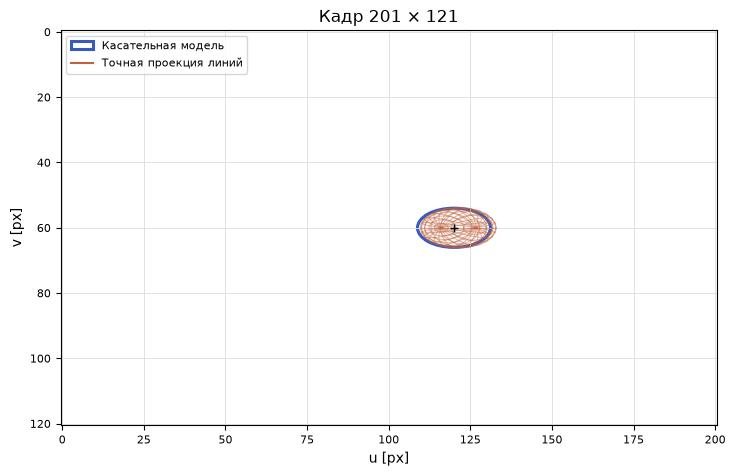

In [4]:
fig = demos.footprint_figure("ru")
plt.show()

## Шесть откликов в одной таблице

У картинки два числа, $u$ и $v$. У смещения в пространстве три, $\Delta x,\Delta y,\Delta z$. Для каждой пары «ответ — причина» есть местный коэффициент. В таблице $J$ строки соответствуют экранным координатам, столбцы — пространственным. Такая таблица частных производных называется **якобианом**. «Частная» означает, что для одного столбца сдвигается только одна координата.

$$
J=
\begin{bmatrix}
f_x/z & 0 & -f_x x/z^2\\
0 & f_y/z & -f_y y/z^2
\end{bmatrix}
=\begin{bmatrix}20&0&-5\\0&20&0\end{bmatrix}.
$$

Здесь $y=0$, поэтому продвижение строго вперёд не меняет $v$. Для смещения $(0.1,0.05,0.2)$ м перемножим первую строку со столбцом: $20\cdot0.1+0\cdot0.05-5\cdot0.2=1$ px. Во второй строке $20\cdot0.05=1$ px. Прибавим к центру $(120,60)$, получим $(121,61)$ px. Точное деление для новой точки $(1.1,0.05,4.2)$ даёт $(120.9524,60.9524)$ px. Меньшее смещение оставит меньшую разницу.

Если шаг вдоль глубины целый метр, якобиан предскажет $120-5=115$ px. Точная точка на глубине 5 м даёт $100+80/5=116$ px. На метр **к** камере прогноз $120+5=125$ px, но точный результат $100+80/3\approx126.667$ px. У прямой одинаковый наклон на обеих сторонах; у перспективного деления наклон меняется по пути.

In [5]:
J = geo.projection_jacobian(mu, focal)
for delta in [[.1,.05,.2],[0,0,1],[0,0,-1]]:
    linear = uv + J @ delta
    exact = geo.project_point(mu+delta, focal, principal)
    print("Δ =", delta, "  linear =", linear, "  exact =", exact)

Δ = [0.1, 0.05, 0.2]   linear = [121.  61.]   exact = [120.9524  60.9524]
Δ = [0, 0, 1]   linear = [115.  60.]   exact = [116.  60.]
Δ = [0, 0, -1]   linear = [125.  60.]   exact = [126.6667  60.    ]


## Расстояние до камеры в долях глубины

В числах выше ближняя точка ошибается сильнее дальней. Откуда такая асимметрия? Зафиксируем $x=1$ м, $f_x=80$ px и глубину центра $z=4$ м. Точное смещение вправо или влево при шаге $h$ по глубине получается вычитанием двух положений. Линейное смещение даёт третья ячейка первой строки якобиана. Оба числа имеют размерность пикселей.

$$
\begin{aligned}
\Delta u_{\rm exact}&=\frac{80}{4+h}-\frac{80}{4}
                      =-\frac{20h}{4+h},\\
\Delta u_{\rm local}&=-5h,\\
\Delta u_{\rm exact}-\Delta u_{\rm local}
 &=\frac{-20h+5h(4+h)}{4+h}=\frac{5h^2}{4+h}.
\end{aligned}
$$

Здесь $h$ подставляется числом метров, а сравнение имеет смысл только при $4+h>0$ и перед плоскостью отсечения. Для шага $+0.4$ точное смещение равно $-8/4.4\approx-1.818$ px, линейное равно $-2$. Промах $0.182$ px. Для $-0.4$ точное смещение равно $8/3.6\approx2.222$ px, линейное равно $2$. Промах уже $0.222$ px. В числителях последней строки один и тот же квадрат. Разница в знаменателе. Приближение к камере делает его меньше.

Полезно сравнить промах с **самим смещением**, а не со всем адресом пикселя. Деление $0.182/1.818$ даёт около одной десятой. Для ближней точки $0.222/2.222$ выходит та же десятая часть. В этом опыте при ненулевом шаге дробь сокращается до $|h|/4$. Поэтому 10 см толщины ощущаются совершенно по-разному в четырёх метрах от камеры и в двадцати сантиметрах. Это вывод для движения по глубине при закреплённом $x$. Движения в других направлениях могут усиливать или компенсировать друг друга.

## Как шесть чисел превращают объём в эллипс

В исходном положении ковариация облачка в системе камеры $\Sigma_c=\mathrm{diag}(0.25,0.09,1)$ м². Числа получились из масштабов $0.5$, $0.3$, $1$ м после возведения в квадрат. Для перемещения по экрану работают коэффициенты $J$. Для двух экранных направлений должны преобразоваться обе стороны ковариации:

$$
\Sigma_2=J\Sigma_c J^{\mathsf T}.
$$

Это прежнее правило «умножение с двух сторон», только теперь между тремя входными и двумя выходными осями. Его можно собрать на пальцах. Вдоль $u$ собственное смещение по $x$ величиной 0.5 м даёт масштаб $20\cdot0.5=10$ px. По $z$ один метр даёт $-5\cdot1=-5$ px. Независимые направления складывают **квадраты** вкладов: $10^2+(-5)^2=125$ px². Чтобы вернуться к длине, берём квадратный корень: $\sqrt{125}\approx11.180$ px. По $v$ действует только $y$: $20\cdot0.3=6$ px, квадрат равен 36 px².

Одна исходная ось должна влиять сразу на $u$ и $v$, чтобы появился перекрёстный вклад. Здесь у $u$ работают $x,z$, у $v$ — только $y$. Поэтому перекрёстный член равен нулю, и итоговая матрица — $\mathrm{diag}(125,36)$. При нулевом ракурсе «Поворот формы» на $45^\circ$ разворачивает длинную и короткую оси на экране. Их поперечные ковариации теперь равны $(0.25-0.09)/2=0.08$ м². Каждая экранная ось увеличивает смещения в 20 раз. Получается $\Sigma_{uv}=20\cdot0.08\cdot20=32$ px². Синий эллипс наклоняется вправо вниз. Матрица $2\times2$ и центр — уже знакомое пятно из урока 4.

А если начальная форма задана в мире? Ориентация камеры $B$ из урока 10 переносит её оси в мир. Из мира **в камеру** смещения преобразуются матрицей $W=B^{\mathsf T}$. Сначала $\Sigma_c=W\Sigma_w W^{\mathsf T}$, затем уже применяется $J$. Перенос центра камеры исчезает для разностей соседних точек, но остаётся в положении центра, от которого зависит сам $J$. В [статье Kerbl и соавторов](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) эти два шага объединены. Здесь мы оставили их раздельными, чтобы видеть, в каких единицах живёт каждая матрица.

In [6]:
cov3 = geo.covariance_3d([.5,.3,1], [1,0,0,0])
cov2 = geo.projected_covariance(mu, cov3, focal)
print("J =\n", J, "\nΣ₂ =\n", cov2, "\nradii =", np.sqrt(np.diag(cov2)), "px")
np.testing.assert_allclose(cov2, np.diag([125,36]))
tilted = geo.covariance_3d([.5,.3,1], geo.axis_angle_quaternion([0,0,1],45))
np.testing.assert_allclose(geo.projected_covariance(mu, tilted, focal), [[93,32],[32,68]])

J =
 [[20.  0. -5.]
 [ 0. 20. -0.]] 
Σ₂ =
 [[125.   0.]
 [  0.  36.]] 
radii = [11.1803  6.    ] px


Откуда справа берётся вторая копия якобиана? У двух отклонений экрана $d_u$ и $d_v$ ковариация — среднее произведение $d_u d_v$, если оба отсчитываются от среднего. Для симметричного облака и линейного преобразования среднее экранное отклонение равно нулю. Допустим, отклики по $u$ собраны в строке $j_u$, а по $v$ в строке $j_v$. Сначала из одного пространственного сдвига $d=(d_x,d_y,d_z)$ получаем два числа $d_u=j_ud$ и $d_v=j_vd$. При их умножении каждое слагаемое из первого числа умножится на каждое из второго. Например, произведение $d_xd_z$ получит множители из столбца $x$ в первой строке и столбца $z$ во второй. После усреднения произведения пространственных отклонений заменятся готовыми ячейками $\Sigma_c$. Так и набирается одна ячейка $j_u\Sigma_c j_v^{\mathsf T}$. Если вместо второй строки взять снова первую, получится средний квадрат $d_u^2$. Все четыре комбинации строк сразу и даёт произведение $J\Sigma_c J^{\mathsf T}$.

## Пятно наклонилось сразу в двух плоскостях

Предыдущая диагональная матрица спрятала интересную часть вычисления. Подвинем центр до $(1,0.5,4)$ м. По горизонтали у камеры всё ещё 80 px фокусного расстояния, а по вертикали теперь 64 px. Главная точка остаётся $(100,60)$. Проекция центра переезжает в $(100+80/4,\ 60+64\cdot0.5/4)=(120,68)$ px. Якобиан в этом месте состоит из строк $(20,0,-5)$ и $(0,16,-2)$ в пикселях на метр. Если приблизить точку к камере, теперь вправо и вниз сдвинутся **обе** координаты. Второй коэффициент глубины перестал быть нулём.

Для новой формы возьмём три независимых числа со средним нулём и разбросом в одну единицу. Назовём их $a,b,c$. Каждое можно вообразить качанием одного рычажка. Первый на единицу отклонения двигает точку на $(0.4,0.2,0)$ м, второй на $(0,0.3,0.2)$ м, третий на $(0,0,0.6)$ м. Это способ породить облако со связью между координатами. Эти три стрелки могут быть косыми друг к другу. Главные оси получившегося облака в таком случае пройдут в других направлениях.

Что получится в строке ковариации для $x$? Горизонталь в пространстве меняет только первый рычажок, значит разброс в квадрате равен $0.4^2=0.16$ м². Тот же рычажок одновременно двигает $y$ на $0.2$ м, поэтому связь $x$ с $y$ равна $0.4\cdot0.2=0.08$ м². У $x$ с $z$ общего рычажка нет, произведение равно нулю. У $y$ и $z$ общий второй рычажок, получается $0.3\cdot0.2=0.06$ м². Квадраты остальных разбросов равны $0.2^2+0.3^2=0.13$ и $0.2^2+0.6^2=0.40$ м². Независимость нужна именно там, где исчезли произведения **разных** рычажков.

Так получается симметричная таблица. Для проверки её можно собрать как $A A^{\mathsf T}$, если столбцы $A$ — три исходные стрелки. Осталось умножить слева на $J$ и справа на $J^{\mathsf T}$. Начнём с первой строки промежуточной таблицы. Умножаем первую строку ковариации на 20, третью на пять и вычитаем последнее произведение из первого. Поэтому на первом месте $20\cdot0.16-5\cdot0=3.2$, на втором $20\cdot0.08-5\cdot0.06=1.3$, на третьем $20\cdot0-5\cdot0.40=-2$. Для второй строки вместо этих множителей берутся $16$ для $y$ и $-2$ для $z$.

$$
\begin{aligned}
J\Sigma_c&=
\begin{bmatrix}3.2&1.3&-2\\1.28&1.96&0.16\end{bmatrix},\\
S_{uu}&=3.2\cdot20+1.3\cdot0+(-2)(-5)=74,\\
S_{uv}&=3.2\cdot0+1.3\cdot16+(-2)(-2)=24.8,\\
S_{vv}&=1.28\cdot0+1.96\cdot16+0.16(-2)=31.04.
\end{aligned}
$$

Промежуточная таблица измерялась в пикселях, умноженных на метры. Последнее умножение на пиксели на метр оставило квадратные пиксели. Вторая строка, первый столбец даёт $1.28\cdot20+0.16(-5)=24.8$. Равенство двух перекрёстных членов служит проверкой и умножения, и транспонирования. Если по ошибке повторить диагональный расчёт для независимых $x,y,z$, часть чисел получится правдоподобной, но наклон и веса конкретных пикселей окажутся другими.

In [7]:
point = np.array([1., .5, 4.])
j = geo.projection_jacobian(point, (80, 64))
arrows = np.array([[.4, 0, 0], [.2, .3, 0], [0, .2, .6]])
sigma = arrows @ arrows.T
screen = geo.projected_covariance(point, sigma, (80, 64))
print("Σc =\n", sigma, "\nJ Σc =\n", j @ sigma, "\nS =\n", screen)
np.testing.assert_allclose(screen, [[74, 24.8], [24.8, 31.04]])
np.testing.assert_allclose(screen, (j @ arrows) @ (j @ arrows).T)

Σc =
 [[0.16 0.08 0.  ]
 [0.08 0.13 0.06]
 [0.   0.06 0.4 ]] 
J Σc =
 [[ 3.2   1.3  -2.  ]
 [ 1.28  1.96  0.16]] 
S =
 [[74.   24.8 ]
 [24.8  31.04]]


## Два пикселя на одинаковом расстоянии

Один пиксель находится на шесть столбцов правее центра и четыре строки ниже. Другой лежит на шесть столбцов правее и четыре строки выше. До обоих на плоской линейке $\sqrt{6^2+4^2}=\sqrt{52}$ px. У наклонённого пятна один пиксель почти вдоль длинной оси, второй ближе к поперечному направлению. Хорошая проверка матрицы — предсказать, какой окажется ярче ещё до построения картинки.

Обозначим смещение $\delta=(d_u,d_v)$. Для таблицы из двух строк обратная матрица строится просто. Угловые элементы диагонали меняются местами, два перекрёстных меняют знак, и всё делится на определитель. Здесь он равен $74\cdot31.04-24.8^2=1681.92$ px⁴. В первом углу числителя осталось $31.04$ px², значит результат имеет единицы обратных квадратных пикселей. Теперь в прежнюю гауссиану на плоскости можно подставить настоящие адреса.

$$
q=\delta^{\mathsf T}S^{-1}\delta
=\frac{31.04d_u^2-2\cdot24.8d_ud_v+74d_v^2}{1681.92}.
$$

У множителя 2 есть видимая причина. Произведение $d_ud_v$ возникает один раз из верхней строки и ещё один раз из нижней. Для пикселя $(126,72)$ произведение положительно и вычитаемая часть уменьшает $q$ до $0.661$. Вес $e^{-0.661/2}\approx0.719$. Для $(126,64)$ меняется только знак вертикального смещения. Получится $q\approx2.076$ и вес $0.354$. Один и тот же радиус линейки дал почти двукратную разницу веса. При удалении перекрёстного члена из ковариации у двух меток получатся равные веса. Сравнение справа на рисунке как раз показывает цену такой потери.

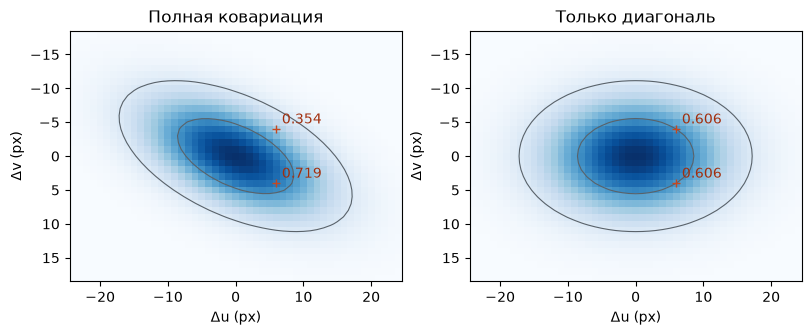

In [8]:
du, dv = np.meshgrid(np.arange(-24, 25), np.arange(-18, 19))
offsets = np.stack([du, dv], axis=-1)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), layout="constrained")
titles = ("Полная ковариация", "Только диагональ") if lang == "ru" else ("Full covariance", "Diagonal only")
for ax, s, title in zip(axes, [screen, np.diag(np.diag(screen))], titles):
    q = np.einsum("...i,ij,...j->...", offsets, np.linalg.inv(s), offsets)
    weights = np.exp(-q / 2)
    ax.imshow(weights, extent=[-24.5, 24.5, 18.5, -18.5], cmap="Blues", vmin=0, vmax=1)
    ax.contour(du, dv, q, levels=[1, 4], colors="#59626a", linewidths=.8)
    for v in [4, -4]:
        weight = weights[v + 18, 6 + 24]
        ax.plot(6, v, marker="+", color="#c54821")
        ax.annotate(f"{weight:.3f}", (6, v), xytext=(4, 4), textcoords="offset points", color="#a22e0d")
    ax.set(title=title, xlabel="Δu (px)", ylabel="Δv (px)", aspect="equal")
plt.show()

## Где синий контур перестаёт успевать

В опыте у ближней плоскости глубина 0.2 м. Пусть у центра $z=2$, а масштаб вдоль глубины 1.5 м. Ближний конец оболочки находится на $2-1.5=0.5$ м. Даже самая ближняя часть ещё перед камерой, но разница между делением на 0.5 и на 2 уже огромна. На рисунке остаётся только часть оранжевой сетки, помещающаяся внутри кадра.

Если опустить глубину центра до 1 м при том же размере, часть поверхности пересечёт плоскость отсечения. Такие точки исключаются из оранжевой сетки. Для центра всё ещё существует якобиан и можно нарисовать синий эллипс. Вычислить эллипс оказалось проще, чем оправдать точность его формы. Кроме того, у самой гауссианы есть бесконечные хвосты; опыт сравнивает выбранную оболочку $D^2=1$, а не интеграл света вдоль луча или точную проекцию всей плотности.

**Опыт.** Центр переместился на оптическую ось в $(0,0,4)$. Изменится ли синий эллипс при удвоении только $s_z$, если собственные оси и камера совпадают?

<details>
<summary>Разбор</summary>

Оба коэффициента глубины равны нулю: $-80\cdot0/16=0$. Значит, внутри линейной модели вклад $s_z$ исчез. Радиусы равны $20\cdot0.5=10$ и $20\cdot0.3=6$ px. Оранжевая сетка при утолщении всё равно изменится, потому что точки вдали от центра имеют свои $x,y,z$.

</details>

**Оценка ошибки.** Насколько ошибётся горизонтальный прогноз для точки на 0.5 м ближе исходного центра $(1,0,4)$?

<details>
<summary>Разбор</summary>

Шаг $\Delta z=-0.5$. Якобиан предсказывает $120+(-5)(-0.5)=122.5$ px. Точное деление даёт $100+80/3.5\approx122.857$ px. Разница примерно 0.357 px. Дальше в сцене таких пятен будет несколько, и к вопросу об их форме добавится вопрос об очерёдности смешивания.

</details>

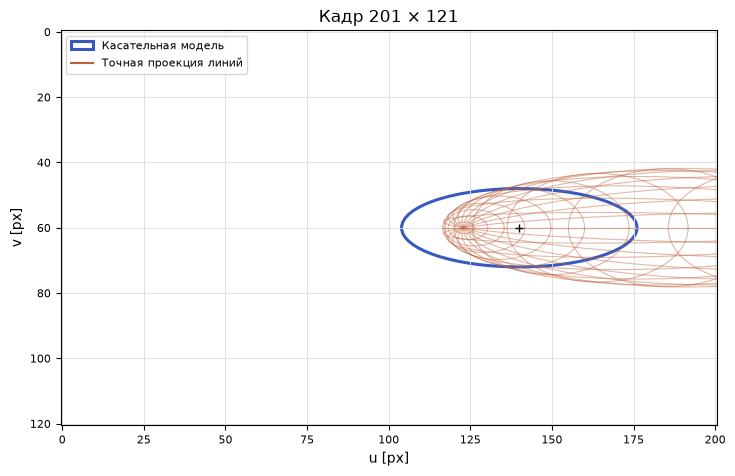

In [9]:
fig = demos.footprint_figure("ru", depth=2, sz=1.5)
plt.show()

## Ещё два способа поймать ошибку в рендере

**Узкий объектив или увеличенная картинка?** Оба фокусных расстояния в несимметричном примере удвоились, главная точка и разрешение прежние. Что произойдёт с центром, радиусами и ковариацией? Сохранится ли вес у смещения $(6,4)$ px?

<details>
<summary>Разбор</summary>

Смещение центра от главной точки было $(20,8)$, станет $(40,16)$. Новый центр $(140,76)$. В каждой строке якобиана теперь множитель 2. Ковариация умножится на $2^2=4$, длины осей эллипса удвоятся. Пиксель на старом смещении окажется ближе к вершине в единицах масштаба. Его $q$ уменьшится вчетверо, вес вырастет с $0.719$ до $e^{-0.661/8}\approx0.921$. Старый вес теперь встретится на смещении $(12,8)$. Изменение поля зрения в таком опыте не создаёт новых деталей в самом облаке.

</details>

**Та же форма в другом месте кадра.** Центр уходит на оптическую ось, а ориентация облака и его исходная косая ковариация остаются прежними. Исчезнет ли наклон синего контура?

<details>
<summary>Разбор</summary>

У нового центра $x=y=0$. Два коэффициента чувствительности к глубине исчезают. Остаются строки $(20,0,0)$ и $(0,16,0)$. Но у исходных $x$ и $y$ всё ещё есть общий первый рычажок, так что перекрёстный член будет $20\cdot0.08\cdot16=25.6$ px². Диагональ станет $(64,33.28)$ px². Наклон сохранился. В одном и том же видимом наклоне могут участвовать и форма объекта, и то, из какой части кадра на него смотрит камера.

</details>